# Long Data: the analysis behind the talk

This notebook makes the four charts in the October 21, 2026 Emerging Technologies Taskforce talk that come from data:

| Chart | Frame | Made in |
|---|---|---|
| `img/deck-themes-by-quarter.pdf` | Analyzing hotline: questions from council | Part 3 |
| `img/deck-records-needed.pdf` | Analyzing hotline: answers from staff | Part 3 |
| `img/hotline-theme-by-records.pdf` | Appendix: which records each theme depends on | Part 3 |
| `img/budget-index.png` | Twenty-two years of the city's budget | Part 4 |

It also prints every hotline count the slides quote. Parts 1 to 3 study the council hotline; Part 4 draws the budget chart from the Charting Boulder budget-history dataset.

Run it from this talk's `code/` folder. Every chart is saved on a white background and uses the City of Boulder's brand identity (bouldercolorado.gov/brand): colors from its "City Colors" palette, and Assistant, the brand's named alternative to its Adobe typeface Adelle Sans. Assistant is in `fonts/`, under the SIL Open Font License (`fonts/OFL.txt`).

In [1]:
import json
import re
import urllib.parse
import urllib.request
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import font_manager

# Where the charts go: the talk's img/ folder, next to this code/ folder
IMG = Path("../img")
# The deck's window: messages received from March 2, 2023 through this date
CUTOFF = "2026-10-15"
# True pulls the hotline from the city's open data layer; False reads the labels this notebook saved last time
PULL_LIVE = True
LABELS = Path("hotline-labels-all.csv")
# budget-history-wide.csv from brianckeegan/charting-boulder-private, 2027-XX-budget-history/
BUDGET_CSV = Path("../../../charting-boulder-private/2027-XX-budget-history/budget-history-wide.csv")

# City of Boulder "City Colors" (bouldercolorado.gov/brand), by their brand names
BOULDER_BLUE, GLACIER_BLUE, BETASSO_BLUE, WINTER_NIGHT = "#406F8C", "#E2EDF2", "#8CB8CA", "#13252D"
BUFFALO_BRONZE, RED_ROCKS_RUST = "#926D2A", "#772618"
# Text in Winter Night; amounts in Boulder Blue; "no records needed" in the lighter Betasso Blue
TEXT, AMOUNT, NONE = WINTER_NIGHT, BOULDER_BLUE, BETASSO_BLUE
# The heat maps' one-hue ramp, light to dark; the lightest is the color of the smallest cell, not the background
AMOUNTS = [GLACIER_BLUE, BETASSO_BLUE, BOULDER_BLUE, WINTER_NIGHT]

# Assistant, the brand's alternative typeface, in its two weights
for weight in ("Regular", "Bold"):
    font_manager.fontManager.addfont(f"fonts/Assistant-{weight}.ttf")
plt.rcParams.update({"font.family": "Assistant", "text.color": TEXT, "axes.labelcolor": TEXT,
                     "xtick.color": TEXT, "ytick.color": TEXT, "figure.facecolor": "white", "axes.facecolor": "white"})

## Part 1: Pull the hotline and sort its traffic

The city publishes every message on the council hotline as an open data layer, "Emails to the City Council Hotline," under a CC0 public-domain license. The layer replaces email addresses and phone numbers with one-way codes; senders' names stay. The query below pages through the layer 1,000 records at a time until the server says nothing is left (`exceededTransferLimit`), so no record is cut off by the page size.

The layer numbers its records newest first, so an `ObjectId` changes as new mail arrives. The window, not the ID, defines the deck's dataset.

In [2]:
URL = ("https://services.arcgis.com/ePKBjXrBZ2vEEgWd/arcgis/rest/services/"
       "Emails_to_the_City_Council_Hotline/FeatureServer/0/query")


def pull():
    """Return every record in the hotline layer as a DataFrame, paging until the server has no more."""
    rows, offset = [], 0
    while True:
        query = urllib.parse.urlencode({"where": "1=1", "outFields": "*", "f": "json", "resultOffset": offset,
                                        "resultRecordCount": 1000, "orderByFields": "ObjectId"})
        page = json.load(urllib.request.urlopen(URL + "?" + query, timeout=60))
        features = page.get("features", [])
        rows += [feature["attributes"] for feature in features]
        if not page.get("exceededTransferLimit"):
            return pd.DataFrame(rows)
        offset += len(features)

Most mail on the layer went to the hotline list, whose subject lines carry `[BoulderCouncilHotline]`. The rest, about one message in eight, is mail sent to council members off the list, and it is set aside.

Each list message is then sorted by who wrote it and what it does:

- **Author.** A message is from council if a council member sent it or signed it; otherwise it is from staff. The signature check reads the last 600 characters of the message's own text.
- **Own text.** A reply quotes the thread below it. `top_segment` keeps only the text above the first quoted header ("From:", "-----Original Message", "On ... wrote:"), so a reply isn't credited with the words it quotes.
- **Function.** A council message with a question mark, or "question" in its subject, is a council question; other council mail is a position or notice. A staff message whose subject marks it as a reply or an answer is a staff response. Other staff mail is a routine report, a procedural note (agendas, packets, memos), or another memo.

In [3]:
COUNCIL = {"Wallach, Mark", "Benjamin, Matthew", "Schuchard, Ryan", "Folkerts, Lauren", "Speer, Nicole", "Marquis, Tina",
           "Winer, Tara", "Brockett, Aaron", "Yates, Bob", "Friend, Rachel", "Adams, Taishya", "Joseph, Junie", "Kaplan, Rob"}
SIGNATURE = (r"(?:Wallach|Benjamin|Schuchard|Folkerts|Speer|Marquis|Winer|Brockett|Yates|Friend|Adams|Joseph|Kaplan"
             r"|Councilmember|Council Member|Mayor Pro Tem)")


def top_segment(body):
    """Return the part of a message its author wrote: the text above the first quoted header, or the first 3,000 characters."""
    match = re.search(r"\n?\s*(From:|-----Original Message|On .{5,80} wrote:|________________________________)", body)
    return body[:match.start()] if match and match.start() > 40 else body[:3000]


def categorize(df):
    """Return the hotline-list messages with their author ("council" or "staff") and their function ("cat")."""
    df = df.copy()
    df["body"] = df.PlainTextBody.fillna("")
    df["subj"] = df.EmailSubject.fillna("")
    lst = df[df.subj.str.contains("BoulderCouncilHotline", case=False)].copy()
    lst["top"] = lst.body.map(top_segment)
    lst["topq"] = lst.top.str.count(r"\?")
    signed = lst.top.str[-600:].str.contains(SIGNATURE, regex=True)
    lst["author"] = ["council" if (sender in COUNCIL or sig) else "staff" for sender, sig in zip(lst.SentFrom, signed)]
    subject = lst.subj.str.lower()
    reply = subject.str.contains(r"\bre:|answer|response|follow[- ]?up|information request", regex=True)
    asks = subject.str.contains("question")

    def function(row, is_reply, is_question):
        if row.author == "council":
            return "council question" if (row.topq >= 1 or is_question) else "council position/notice"
        if is_reply or is_question:
            return "staff response"
        if re.search(r"revenue report|disbursement|monthly|quarterly", row.subj.lower()):
            return "staff routine report"
        if re.search(r"agenda|consent|addendum|memo|calendar|cancel|packet|item \d", row.subj.lower()):
            return "staff procedural"
        return "staff other memo"

    lst["cat"] = [function(row, rp, qs) for row, rp, qs in zip(lst.itertuples(), reply, asks)]
    return lst

In [4]:
if PULL_LIVE:
    raw = pull()
    # Keep the deck's window: everything received through the cutoff date
    raw["received"] = pd.to_datetime(raw.ReceivedDate, utc=True, format="mixed")
    raw = raw[raw.received.dt.date <= pd.Timestamp(CUTOFF).date()].reset_index(drop=True)
    lst = categorize(raw)
    print(f"Records through {CUTOFF}: {len(raw)}. On the list: {len(lst)}. Off the list, set aside: {len(raw) - len(lst)}")
    print(f"Received {raw.received.min():%B %-d, %Y} to {raw.received.max():%B %-d, %Y}")
    print(lst.cat.value_counts().to_string())
    questions = lst[lst.cat == "council question"]
    print(f"Question marks in council question posts: {int(questions.topq.sum())}")

Records through 2026-10-15: 904. On the list: 797. Off the list, set aside: 107
Received March 2, 2023 to October 15, 2026
cat
council question           209
council position/notice    173
staff procedural           150
staff response             144
staff other memo           104
staff routine report        17
Question marks in council question posts: 1092


The talk's table of 40 staff answers comes from a random sample of the staff responses, drawn with a fixed seed so it can be drawn again. Each sampled answer was read and coded by hand, by one coder, as procedural, a lookup, facts plus judgment, or new analysis. The sample was drawn on September 15, 2026, so it comes from the staff responses received by then, even though the rest of the analysis runs to the cutoff above. That coding sheet is not in this folder; the cell lists the sample so the coding can be checked or redone.

In [5]:
# The hand-coded sample was drawn from the staff responses received through this date
SAMPLE_CUTOFF = "2026-09-15"
if PULL_LIVE:
    coded_window = lst[(lst.cat == "staff response") & (lst.received.dt.date <= pd.Timestamp(SAMPLE_CUTOFF).date())]
    sample = coded_window.sample(40, random_state=7)
    print(sample[["ReceivedDate", "EmailSubject"]].sort_values("ReceivedDate").to_string(index=False, max_colwidth=90))

                      ReceivedDate                                                                               EmailSubject
2023-04-07 11:01:13.0000000 +00:00                                                  [BoulderCouncilHotline] Re: JTTF language
2023-06-20 09:14:41.0000000 +00:00                      [BoulderCouncilHotline] Better Public Meetings appointees - follow up
2023-06-20 10:03:59.0000000 +00:00                  [BoulderCouncilHotline] Re: Better Public Meetings appointees - follow up
2023-07-11 19:13:03.0000000 +00:00                                   [BoulderCouncilHotline] Re: Sales Tax Voter Poll Results
2023-07-24 15:59:35.0000000 +00:00        [BoulderCouncilHotline] Re: Weller Code of Conduct Complaint - Final Determination 
2023-07-31 15:35:28.0000000 +00:00                     [BoulderCouncilHotline] Re: update on homelessness services evaluation
2023-09-28 13:08:49.0000000 +00:00 [BoulderCouncilHotline] Re: Thoughts and questions ahead of my absence from Thursda

## Part 2: Label each message by theme and by the records it needs

Two sets of keyword dictionaries label each message, using its subject line and its own text, after the boilerplate below is stripped: links, signatures, addresses, the hashed contact codes, legal notices, and department names that would otherwise match a theme in every signature.

- **Nine policy themes.** A message that matches none is "Meetings and procedure only."
- **Eight kinds of records** an answer would need. A message that matches none is "No records needed."

The labels are multi-label: one message can touch several themes and need several kinds of record. The dictionaries are short on purpose, so a reader can see each rule and dispute it. Keywords see words, not intent, so treat the results as a map of what council asks about, not as measurement. A spot check: in 25 messages read by hand, the keywords named the main theme correctly in about 22.

In [6]:
THEMES = {
    "Budget and finance": r"budget|revenue|sales tax|property tax|\btax(es)?\b|\bbonds?\b|debt|fiscal|appropriat|general fund|financial|disbursement|\bfees?\b|funding|city funds|investment",
    "Housing and land use": r"housing|zoning|land use|density|occupancy|\badus?\b|affordable|development review|annex|bvcp|comprehensive plan|planning reserve|area iii|parking minimum|\bamps\b|site review|cu south|middle housing",
    "Homelessness and human services": r"homeless|unhoused|shelter|safe outdoor|\bsos\b|human services|\bhhs\b|behavioral health|encampment|high utilizer",
    "Public safety and policing": r"police|crime|public safety|oversight panel|\bjttf\b|fire department|firefight|fire-rescue|municipal court|nuisance|enforcement|natural medicine",
    "Wildfire, climate and environment": r"wildfire|climate|emission|\bcwpp\b|water ?wise|resilien|flood|open space|sustainab|energy|xcel|electrif|pollinat|\btrees?\b",
    "Water and utilities": r"\bwater\b|utilit|stormwater|wastewater|\bfiber\b|broadband|\bpower\b",
    "Transportation and airport": r"transport|airport|\bbikes?\b|bicycl|traffic|transit|\broads?\b|mobility|vision zero|trench|parking",
    "Economy and downtown": r"\bdda\b|downtown|economic|business|minimum wage|tipped|\btips?\b|retail|university hill|commercial|library district",
    "Governance, elections and ballot": r"ballot|election|charter|rules of procedure|council rules|code of conduct|mayor pro tem|boards? and commissions?|appoint|policy statement|legislat|polling|campaign|liaison|ethics",
}

DATA_NEEDS = {
    "Financial records": r"budget|revenue|\bcosts?\b|\$\s?\d|funding|\bfunds?\b|\btax|expenditure|debt|appropriat|dollars|financial",
    "Legal and code text": r"ordinance|\bcode\b(?! of conduct)|charter|resolution|rules of procedure|agreement|contract|\bleases?\b|legal|statute|c\.r\.s|state law|regulation",
    "Meeting records": r"\bmemo|packet|\bminutes\b|council direction|previous council|prior council|previously|last year|recording|attachment [a-z]\b|staff report",
    "Plans and studies": r"(master|comprehensive|action|strategic|area|capital|climate|transportation|housing|wildfire|protection|work) ?plans?\b|\bplans? (for|to address)|bvcp|\bstudy\b(?! session)|studies|consultant|assessment|strategy|analysis|\breports?\b",
    "Program and operational data": r"\bdata\b|number of|how many|clients|outcomes?|metrics?|statistic|staffing|\bfte\b|capacity|served|\brates?\b|utilization|performance",
    "Spatial and land records": r"\bmaps?\b|parcel|\bzon(e|es|ing)\b|permits?|annex|acres?|\bsites?\b|neighborhood|subcommunity|corridor|propert(y|ies)(?! tax)",
    "Survey and public input": r"survey|\bpoll|public comment|community input|engagement|feedback|open comment|residents said",
    "External and peer data": r"\bcounty\b|\bthe state\b|state law|state legislat|statewide|state funding|state demograph|federal|drcog|\bcu\b|university|peer|other cities|regional|census|demograph|colorado",
}

BOILERPLATE = [
    r"https?://\S+", r"\[[0-9a-f]{64}\]", r"ATTORNEY-CLIENT PRIVILEGE.*", r"CONFIDENTIALITY NOTICE.*",
    r"1777 Broadway[^\n]*", r"\S*bouldercolorado\.gov\S*", r"City of Boulder,? Colorado",
    r"Boulder,? CO(lorado)?( 80\d{3})?", r"\(?pronouns?[^)\n]*\)?", r"What.s This\??",
    r"Office hours and newsletter[^\n]*", r"subscribe at \S+", r"\S+@\S+",
    r"(Department of )?Housing (and|&) Human Services", r"Planning (and|&) Development Services",
    r"Transportation (and|&) Mobility", r"Facilities (and|&) Fleet", r"Parks (and|&) Recreation",
    r"Open Space (and|&) Mountain Parks", r"City Attorney.?s Office", r"City Manager.?s Office",
    r"Climate Initiatives", r"Community Vitality",
]


def clean(text):
    """Strip links, signatures, addresses, hashed contacts, and boilerplate from a message."""
    for pattern in BOILERPLATE:
        text = re.sub(pattern, " ", text, flags=re.I | re.S)
    return text


def label(text, table):
    """Return the names in table whose pattern matches text."""
    lowered = text.lower()
    return [name for name, pattern in table.items() if re.search(pattern, lowered)]

In [7]:
if PULL_LIVE:
    subject = lst.subj.str.replace(r"\[BoulderCouncilHotline\]", "", regex=True)
    lst["text"] = (subject + " \n " + lst.top.str[:4000]).map(clean)
    lst["quarter"] = lst.received.dt.tz_convert(None).dt.to_period("Q").astype(str)
    lst["themes"] = lst.text.map(lambda text: label(text, THEMES) or ["Meetings and procedure only"])
    lst["needs"] = lst.text.map(lambda text: label(text, DATA_NEEDS) or ["No records needed"])
    # Save the labels, one row per message, so the charts can be redrawn without pulling again
    saved = lst[["ObjectId", "ReceivedDate", "quarter", "SentFrom", "EmailSubject", "cat", "themes", "needs"]].copy()
    saved["ReceivedDate"] = lst.received.dt.strftime("%Y-%m-%d")
    for column in ("themes", "needs"):
        saved[column] = saved[column].str.join("; ")
    saved.to_csv(LABELS, index=False)
else:
    lst = pd.read_csv(LABELS)
    for column in ("themes", "needs"):
        lst[column] = lst[column].str.split("; ")
print(f"{len(lst)} labeled messages")

797 labeled messages


## Part 3: The hotline charts and the numbers on the slides

Each chart counts shares, not messages, because the number of messages varies from quarter to quarter and theme to theme. Because the labels are multi-label, shares across themes or record kinds add up to more than 100%.

In [8]:
QA = {"council question", "staff response"}
THEME_ORDER = ["Budget and finance", "Housing and land use", "Governance, elections and ballot", "Transportation and airport",
               "Economy and downtown", "Wildfire, climate and environment", "Public safety and policing", "Water and utilities",
               "Homelessness and human services", "Meetings and procedure only"]
THEME_SHORT = {"Governance, elections and ballot": "Governance and ballot", "Transportation and airport": "Transportation, airport",
               "Economy and downtown": "Economy, downtown", "Wildfire, climate and environment": "Wildfire and climate",
               "Public safety and policing": "Public safety", "Homelessness and human services": "Homelessness",
               "Meetings and procedure only": "Procedure only"}
NEED_ORDER = ["Financial records", "Program and operational data", "Plans and studies", "Meeting records", "Legal and code text",
              "External and peer data", "Spatial and land records", "Survey and public input", "No records needed"]


def heatmap(ax, table, xsize=10):
    """Draw table, rows by columns of percentages, as a labeled heat map from its smallest value to its largest."""
    cmap = mcolors.LinearSegmentedColormap.from_list("boulder_blues", AMOUNTS)
    low, top = table.to_numpy().min(), table.to_numpy().max()
    ax.imshow(table.to_numpy(), cmap=cmap, vmin=low, vmax=top, aspect="auto")
    for (i, j), value in pd.DataFrame(table.to_numpy()).stack().items():
        dark = value > low + 0.55 * (top - low)
        ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=9, color="white" if dark else TEXT)
    ax.set_yticks(range(len(table.index)), table.index)
    ax.set_xticks(range(len(table.columns)), table.columns, fontsize=xsize)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

**What council asks about.** For each quarter, the share of that quarter's messages that touch each theme. The chart shows complete quarters only: a quarter the cutoff cuts short holds too few messages for its shares to mean much, so it is left off the chart, though its messages count everywhere else.

Left off the chart: 2026Q4, cut short by the cutoff, with 8 messages


year                               2023  2024  2025  2026
themes                                                   
Budget and finance                 33.0  35.0  43.0  45.0
Wildfire, climate and environment  11.0  20.0  29.0  34.0
Homelessness and human services    13.0  13.0  13.0   1.0


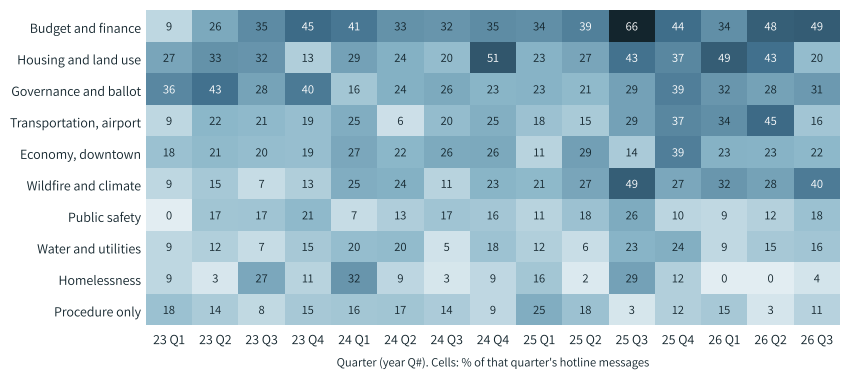

In [9]:
themes = lst.explode("themes")
per_quarter = lst.groupby("quarter").size()
share = themes.groupby(["themes", "quarter"]).size().unstack(fill_value=0) / per_quarter * 100
# Keep the quarters that end on or before the cutoff
complete = [q for q in share.columns if pd.Period(q, freq="Q").end_time.date() <= pd.Timestamp(CUTOFF).date()]
for q in sorted(set(share.columns) - set(complete)):
    print(f"Left off the chart: {q}, cut short by the cutoff, with {per_quarter[q]} messages")
share = share[complete].reindex(THEME_ORDER).fillna(0).rename(index=lambda theme: THEME_SHORT.get(theme, theme))
share.columns = [f"{quarter[2:4]} {quarter[4:]}" for quarter in share.columns]  # 2023Q1 -> 23 Q1

fig, ax = plt.subplots(figsize=(8.6, 3.9), facecolor="white")
heatmap(ax, share)
ax.set_xlabel("Quarter (year Q#). Cells: % of that quarter's hotline messages", fontsize=9)
fig.tight_layout()
fig.savefig(IMG / "deck-themes-by-quarter.pdf", facecolor="white")

# The shares by year that the slides quote
lst["year"] = lst.quarter.str[:4]
by_year = lst.explode("themes").groupby(["year", "themes"]).size() / lst.groupby("year").size() * 100
print(by_year.unstack().round(0).T.loc[["Budget and finance", "Wildfire, climate and environment", "Homelessness and human services"]].to_string())

**What answers need.** Among the council questions and staff responses, where a need for records is real, the share that need each kind of record.

353 questions and answers


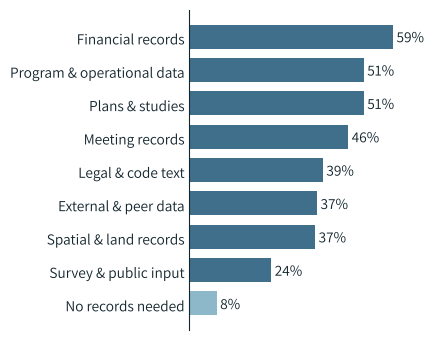

In [10]:
qa = lst[lst.cat.isin(QA)]
need = (qa.explode("needs").needs.value_counts() / len(qa) * 100).reindex(NEED_ORDER).fillna(0)

fig, ax = plt.subplots(figsize=(4.4, 3.5), facecolor="white")
colors = [NONE if name == "No records needed" else AMOUNT for name in need.index]
ax.barh([name.replace(" and ", " & ") for name in need.index], need.to_numpy(), color=colors, height=0.72)
for y, value in enumerate(need.to_numpy()):
    ax.text(value + 1, y, f"{value:.0f}%", va="center", fontsize=11)
ax.invert_yaxis()
ax.set_xticks([])
ax.tick_params(axis="y", length=0, labelsize=11)
for side in ("top", "right", "bottom"):
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color(TEXT)
fig.tight_layout()
fig.savefig(IMG / "deck-records-needed.pdf", facecolor="white")
print(f"{len(qa)} questions and answers")

**Staff answers alone**, for the summary on the slide "Analyzing hotline: answers from staff": the kinds of records named in staff answers, how many kinds each answer draws on, and how often council's questions and staff's answers each mention financial records.

In [11]:
staff = lst[lst.cat == "staff response"]
council = lst[lst.cat == "council question"]
print(f"{len(staff)} staff answers")
print((staff.explode("needs").needs.value_counts() / len(staff) * 100).round(0).to_string())
kinds = staff.needs.map(lambda needs: len([n for n in needs if n != "No records needed"]))
print(f"Three or more kinds of records: {(kinds >= 3).mean():.0%}")
financial = lambda frame: frame.needs.map(lambda needs: "Financial records" in needs).mean()
print(f"Financial records named: council questions {financial(council):.0%}, staff answers {financial(staff):.0%}")

144 staff answers
needs
Plans and studies               47.0
Financial records               43.0
Program and operational data    39.0
Legal and code text             38.0
Meeting records                 35.0
Spatial and land records        33.0
External and peer data          31.0
Survey and public input         26.0
No records needed               14.0
Three or more kinds of records: 56%
Financial records named: council questions 70%, staff answers 43%


**Which records each theme depends on.** Within each theme's questions and answers, the share that need each kind of record.

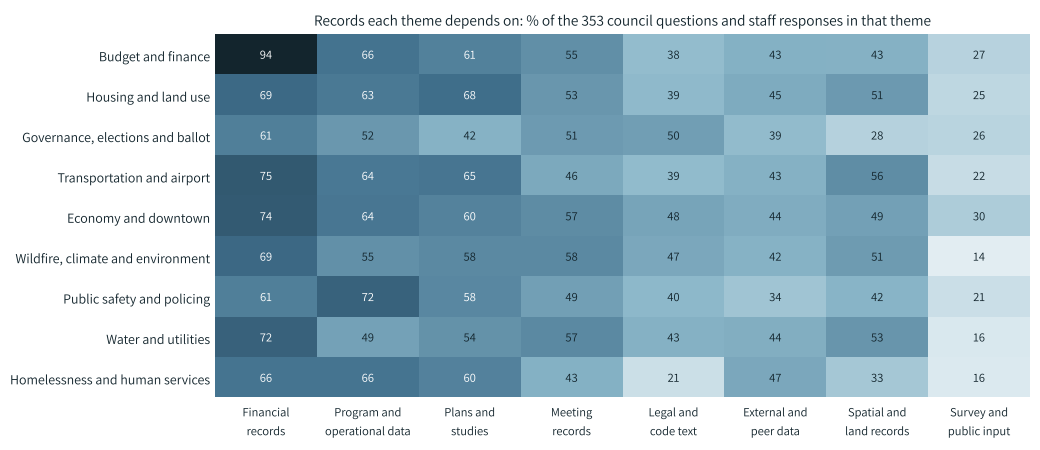

In [12]:
pairs = qa.explode("themes").explode("needs").reset_index(drop=True)  # one row per theme and need
in_theme = qa.explode("themes").themes.value_counts()
by_theme = pd.crosstab(pairs.themes, pairs.needs).div(in_theme, axis=0).mul(100)
by_theme = by_theme.reindex(index=THEME_ORDER[:-1], columns=NEED_ORDER[:-1]).fillna(0)
# Two lines a label, broken after "and" or before the noun, so neighbors don't touch
by_theme.columns = [c.replace(" and ", " and\n") if " and " in c else c.replace(" ", "\n") for c in by_theme.columns]

fig, ax = plt.subplots(figsize=(10.5, 4.6), facecolor="white")
heatmap(ax, by_theme, xsize=9)
ax.set_title(f"Records each theme depends on: % of the {len(qa)} council questions and staff responses in that theme", fontsize=11)
fig.tight_layout()
fig.savefig(IMG / "hotline-theme-by-records.pdf", facecolor="white")

## Part 4: Twenty-two years of the city's budget

The budget chart reads `budget-history-wide.csv` from the Charting Boulder budget-history folder, which transcribes the city's budget books and annual financial reports and checks each figure against the totals printed beside it. Its data dictionary says which version of each figure the wide file keeps:

- **Staff:** adopted full-time-equivalent positions.
- **Sales and use tax, property tax:** audited collections through 2025, and the adopted budget for 2026, drawn dashed.
- **Capital:** the adopted capital budget, a plan rather than actual capital spending. It starts in 2005.

So 2005 is the base year, the first with all four series, and each series is divided by its 2005 value. Money is in nominal dollars, not adjusted for inflation. The chart is 16:9, 1920 by 1080 pixels, on white.

Capital budget: 29.11 in 2005, 113.30 in 2026, index 389; peak 652 in 2025
Property tax: 19.39 in 2005, 59.17 in 2026, index 305; peak 316 in 2024
Sales and use tax: 76.62 in 2005, 179.64 in 2026, index 234; peak 238 in 2025
Staff (FTE): 1212.11 in 2005, 1548.28 in 2026, index 128; peak 128 in 2026


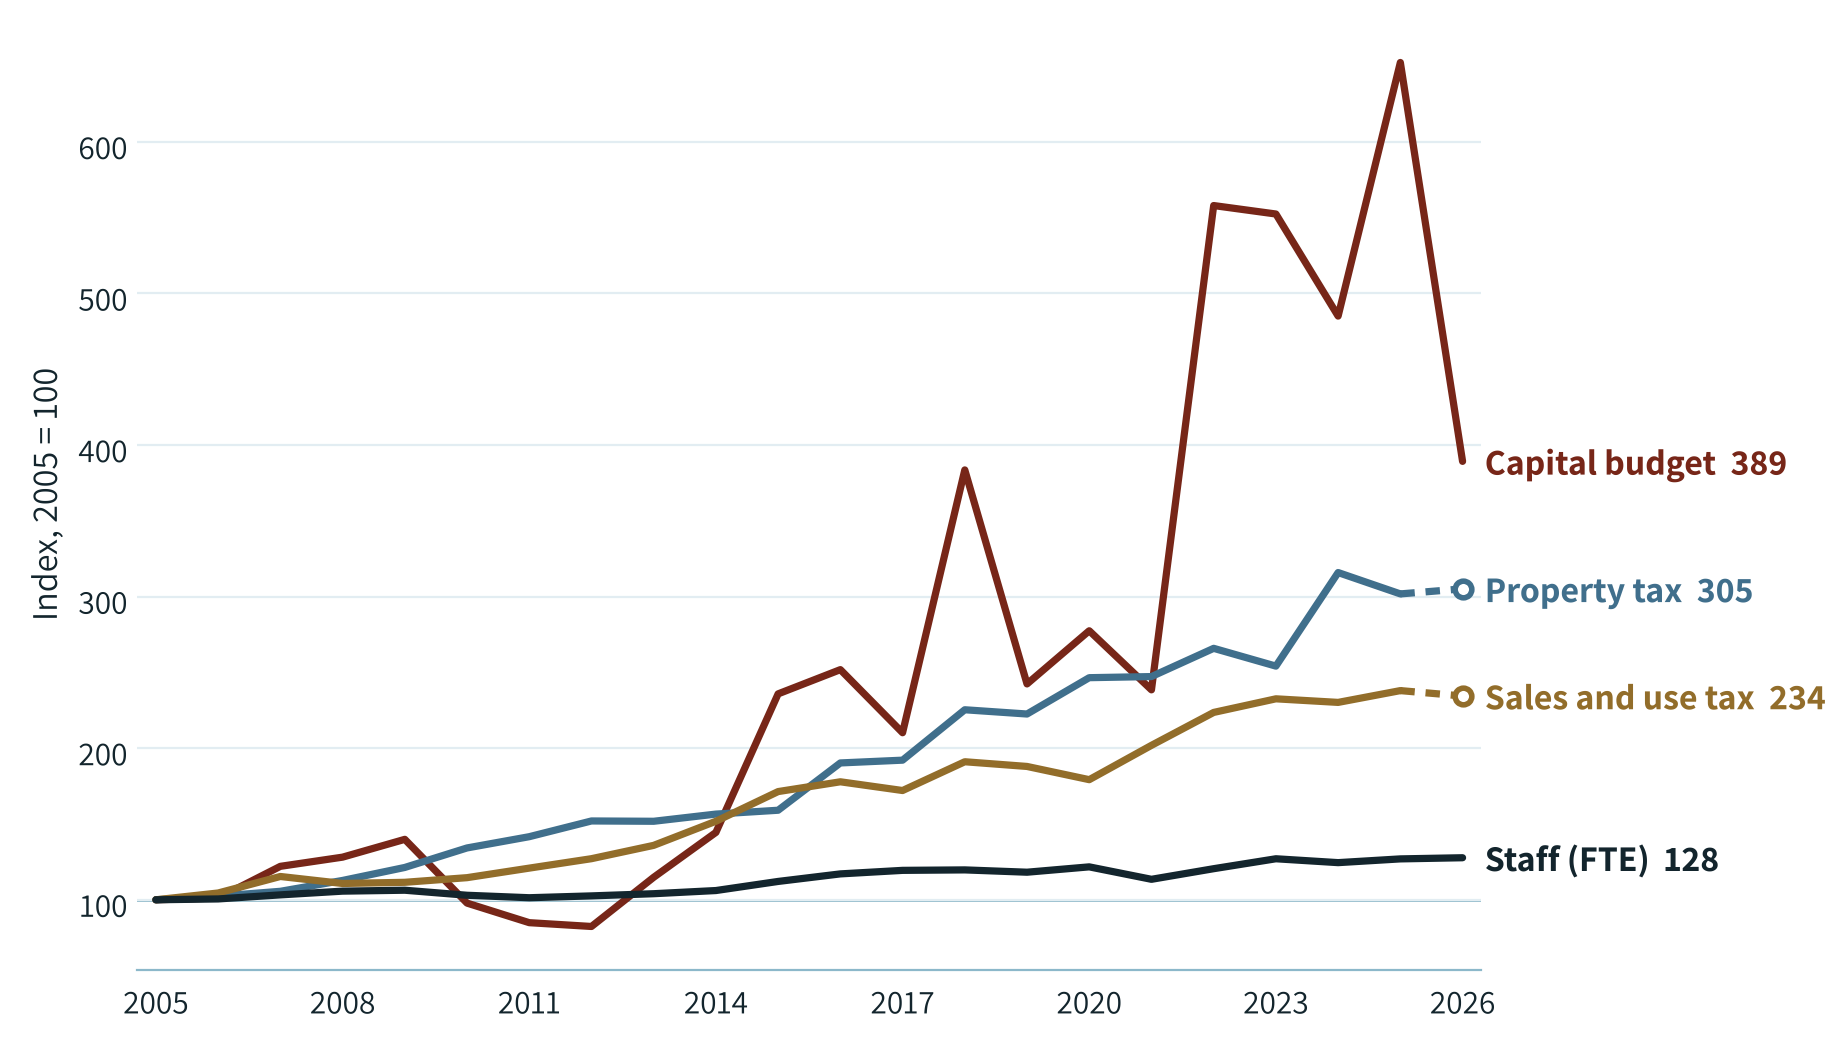

In [13]:
BASE_YEAR, LAST_YEAR = 2005, 2026
# Column in the wide file, label on the chart, and brand color. These four of the brand's colors each reach 4.5:1 on white,
# and every pair stays at least 22 apart (CIELAB delta E) under normal vision and simulated deutan, protan, and tritan vision
SERIES = [("budget_capital", "Capital budget", RED_ROCKS_RUST), ("property_tax_revenue", "Property tax", BOULDER_BLUE),
          ("salesuse_total", "Sales and use tax", BUFFALO_BRONZE), ("staffing_fte", "Staff (FTE)", WINTER_NIGHT)]

wide = pd.read_csv(BUDGET_CSV).set_index("year").loc[BASE_YEAR:LAST_YEAR]
fig, ax = plt.subplots(figsize=(9.6, 5.4), dpi=200, facecolor="white")
for column, label_text, color in SERIES:
    values = wide[column]
    assert values.notna().all(), f"{column} has a gap between {BASE_YEAR} and {LAST_YEAR}"
    index = values / values.loc[BASE_YEAR] * 100
    # Years that are collections draw solid; a final budget year draws dashed, with an open marker
    basis = wide[column + "_basis"]
    closed = basis == "actual" if (basis == "actual").any() else basis.notna()
    ax.plot(index.index[closed], index[closed], color=color, linewidth=2.6, solid_capstyle="round")
    if not closed.all():
        start = index.index[closed][-1]
        ax.plot(index.loc[start:].index, index.loc[start:], color=color, linewidth=2.6, linestyle=(0, (2, 1.5)))
        ax.plot(index.index[~closed], index[~closed], "o", color=color, markerfacecolor="white", markersize=6, markeredgewidth=2)
    ax.annotate(f"{label_text}  {index.iloc[-1]:.0f}", (index.index[-1], index.iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=13, color=color, fontweight="bold")
    print(f"{label_text}: {values.loc[BASE_YEAR]:.2f} in {BASE_YEAR}, {values.iloc[-1]:.2f} in {LAST_YEAR}, "
          f"index {index.iloc[-1]:.0f}; peak {index.max():.0f} in {index.idxmax()}")

ax.axhline(100, color=BETASSO_BLUE, linewidth=1, zorder=0)
ax.set_xlim(BASE_YEAR - 0.3, LAST_YEAR + 0.3)
ax.set_xticks(range(BASE_YEAR, LAST_YEAR + 1, 3))
ax.set_ylabel(f"Index, {BASE_YEAR} = 100", fontsize=13)
ax.tick_params(labelsize=12, length=0)
ax.grid(axis="y", color=GLACIER_BLUE, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(BETASSO_BLUE)
# No footnote in the image: the slide states the bases and the source, at a size the room can read
fig.subplots_adjust(left=0.08, right=0.78, top=0.96, bottom=0.08)
fig.savefig(IMG / "budget-index.png", facecolor="white")